In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
%matplotlib inline

dfraw = pd.read_excel('WHR2018Chapter2OnlineData.xlsx', sheet_name='Table2.1')
cols_to_include = ['country', 'year', 'Life Ladder', 
                   'Positive affect','Negative affect',
                   'Log GDP per capita', 'Social support',
                   'Healthy life expectancy at birth', 
                   'Freedom to make life choices', 
                   'Generosity', 'Perceptions of corruption']
renaming = {'Life Ladder': 'Happiness', 
            'Log GDP per capita': 'LogGDP', 
            'Social support': 'Support', 
            'Healthy life expectancy at birth': 'Life', 
            'Freedom to make life choices': 'Freedom', 
            'Perceptions of corruption': 'Corruption', 
            'Positive affect': 'Positive', 
            'Negative affect': 'Negative'}
df = dfraw[cols_to_include].rename(renaming, axis=1)
key_vars = ['Happiness', 'LogGDP', 'Support', 'Life', 'Freedom', 'Generosity', 'Corruption', 'Positive', 'Negative']

# read in data from SupportingFactors worksheet into a new dataframe dfsupp
dfsupp = pd.read_excel('WHR2018Chapter2OnlineData.xlsx', sheet_name='SupportingFactors')

# extract out region information from SupportingFactors dataframe
regions = dfsupp[['country', 'Region indicator']].rename({'Region indicator': 'region'}, axis=1)

# compute the mean values of all the WHR data for each country, averaging over all years in the dataset
dfmean = df.groupby('country').mean().drop('year', axis=1)

# merge the mean WHR data with the region information extracted previously
df2 = pd.merge(dfmean, regions, on='country').dropna()

# set the index of df2 to be the country name
df2.set_index('country', inplace=True)

# import the StandardScaler
from sklearn.preprocessing import StandardScaler

# extract out the numerical data and scale it to zero mean and unit standard deviation
X = df2[key_vars]
scaler = StandardScaler().fit(X)
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns = X.columns, index = X.index)


# examine the df2 dataframe -- mean WHR values for each country, along with associated regions
df2

,Happiness,Positive,Negative,LogGDP,Support,Life,Freedom,Generosity,Corruption,region
country,,,,,,,,,,
Afghanistan,3.806614,0.580873,0.301283,7.419697,0.517146,50.838271,0.544895,0.118428,0.826794,South Asia
Albania,4.988791,0.642628,0.303256,9.247059,0.723204,68.027213,0.626155,-0.105019,0.859691,Central and Eastern Europe
Algeria,5.555004,0.616524,0.265460,9.501728,0.804633,64.984461,0.536398,-0.208236,0.661478,Middle East and North Africa
Angola,4.420299,0.613339,0.351173,8.713935,0.737973,51.729801,0.455957,-0.077940,0.867018,Sub-Saharan Africa
Argentina,6.406131,0.840998,0.273187,9.826051,0.906080,66.764205,0.753122,-0.154544,0.844038,Latin America and Caribbean
...,...,...,...,...,...,...,...,...,...,...
Venezuela,6.414997,0.823428,0.219652,9.706075,0.925062,64.120754,0.682923,-0.192087,0.782355,Latin America and Caribbean
Vietnam,5.293268,0.631631,0.209818,8.477400,0.827200,65.357492,0.871811,0.019168,0.781401,Southeast Asia
Yemen,3.969106,0.536306,0.299466,8.191046,0.721817,54.056593,0.626482,-0.132600,0.833238,Middle East and North Africa


In [5]:
X_scaled

,Happiness,LogGDP,Support,Life,Freedom,Generosity,Corruption,Positive,Negative
country,,,,,,,,,
Afghanistan,-1.443128,-1.438896,-2.425953,-1.333584,-1.397623,0.735439,0.451854,-1.262731,0.471370
Albania,-0.360792,0.054466,-0.681799,0.776161,-0.776670,-0.719736,0.632648,-0.638194,0.499009
Algeria,0.157600,0.262588,0.007447,0.402698,-1.462554,-1.391919,-0.456675,-0.902184,-0.030449
Angola,-0.881273,-0.381215,-0.556782,-1.224159,-2.077245,-0.543385,0.672914,-0.934399,1.170248
Argentina,0.936845,0.527632,0.866136,0.621142,0.193546,-1.042257,0.546624,1.367958,0.077797
...,...,...,...,...,...,...,...,...,...
Venezuela,0.944963,0.429584,1.026807,0.296688,-0.342879,-1.286749,0.207632,1.190270,-0.672139
Vietnam,-0.082030,-0.574517,0.198462,0.448484,1.100508,0.089020,0.202390,-0.749403,-0.809898
Yemen,-1.294360,-0.808532,-0.693534,-0.938572,-0.774178,-0.899352,0.487271,-1.713444,0.445918


<AxesSubplot:ylabel='country'>

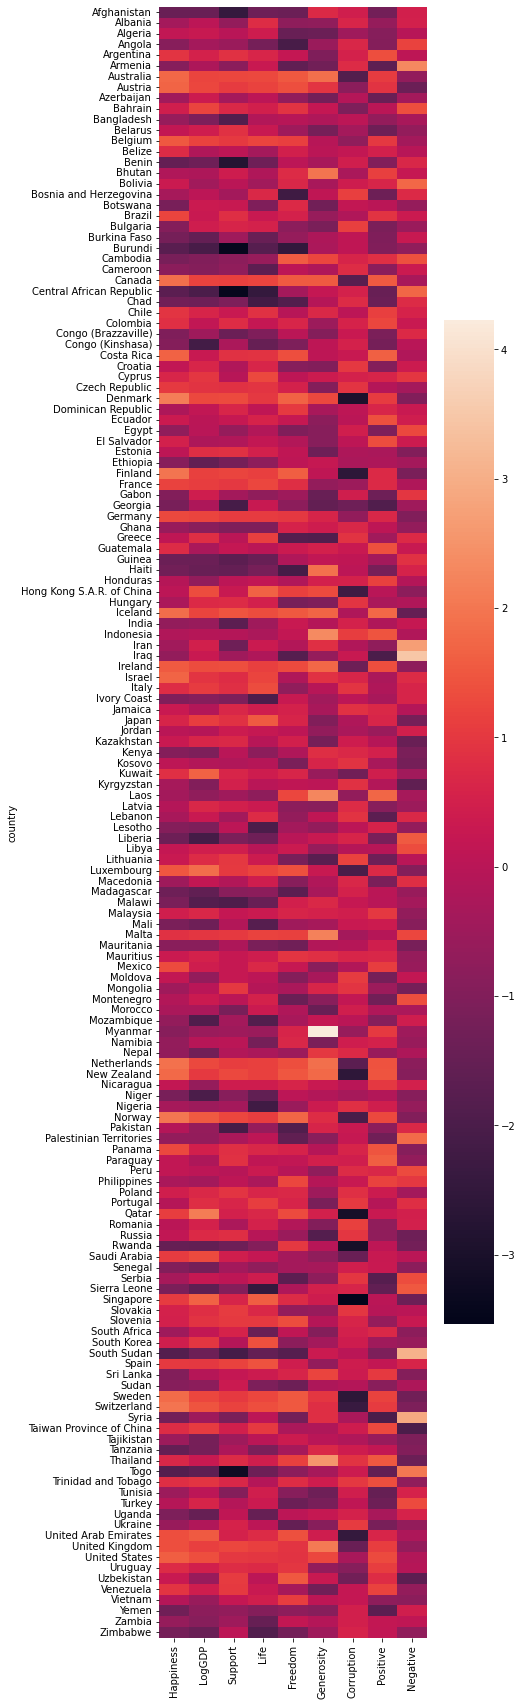

In [7]:
plt.figure(figsize=(6, 30))
sns.heatmap(X_scaled)

In [8]:
k = df2['region'].nunique()
print(k)

10


In [9]:
from sklearn.cluster import KMeans

kcluster = KMeans(n_clusters=k)
kcluster.fit(X_scaled)

KMeans(n_clusters=10)

In [10]:
kcluster.labels_

array([7, 2, 0, 2, 6, 2, 1, 1, 0, 4, 5, 0, 6, 8, 7, 9, 8, 2, 0, 6, 0, 3,
       7, 8, 3, 1, 7, 3, 4, 8, 3, 3, 6, 0, 4, 4, 1, 8, 8, 2, 8, 0, 5, 1,
       6, 2, 2, 1, 5, 0, 8, 3, 7, 8, 1, 0, 1, 5, 9, 2, 2, 1, 4, 4, 3, 8,
       6, 0, 0, 5, 0, 6, 5, 9, 0, 2, 5, 3, 4, 0, 1, 2, 5, 5, 8, 5, 4, 5,
       8, 6, 0, 0, 2, 0, 3, 9, 8, 5, 1, 1, 8, 5, 5, 1, 7, 2, 6, 8, 8, 8,
       4, 4, 1, 0, 0, 5, 6, 5, 2, 3, 1, 0, 4, 8, 0, 7, 4, 9, 3, 1, 1, 2,
       6, 5, 5, 9, 7, 8, 2, 2, 3, 0, 1, 1, 1, 6, 6, 6, 8, 3, 5, 5],
      dtype=int32)

In [11]:
df2_clustered = df2.copy()
df2_clustered['klabel'] = kcluster.labels_

X_scaled_clustered = X_scaled.copy()
X_scaled_clustered['klabel'] = kcluster.labels_

df2_clustered

,Happiness,Positive,Negative,LogGDP,Support,Life,Freedom,Generosity,Corruption,region,klabel
country,,,,,,,,,,,
Afghanistan,3.806614,0.580873,0.301283,7.419697,0.517146,50.838271,0.544895,0.118428,0.826794,South Asia,7
Albania,4.988791,0.642628,0.303256,9.247059,0.723204,68.027213,0.626155,-0.105019,0.859691,Central and Eastern Europe,2
Algeria,5.555004,0.616524,0.265460,9.501728,0.804633,64.984461,0.536398,-0.208236,0.661478,Middle East and North Africa,0
Angola,4.420299,0.613339,0.351173,8.713935,0.737973,51.729801,0.455957,-0.077940,0.867018,Sub-Saharan Africa,2
Argentina,6.406131,0.840998,0.273187,9.826051,0.906080,66.764205,0.753122,-0.154544,0.844038,Latin America and Caribbean,6
...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,6.414997,0.823428,0.219652,9.706075,0.925062,64.120754,0.682923,-0.192087,0.782355,Latin America and Caribbean,6
Vietnam,5.293268,0.631631,0.209818,8.477400,0.827200,65.357492,0.871811,0.019168,0.781401,Southeast Asia,8
Yemen,3.969106,0.536306,0.299466,8.191046,0.721817,54.056593,0.626482,-0.132600,0.833238,Middle East and North Africa,3


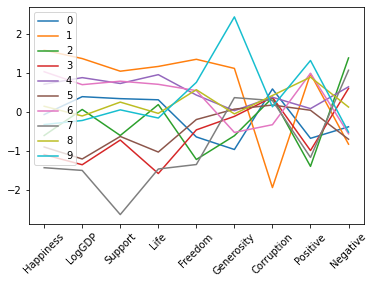

In [12]:
for i in range(k):
    plt.plot(kcluster.cluster_centers_[i], label=i)
plt.xticks(range(9), key_vars, rotation=45)
plt.legend()

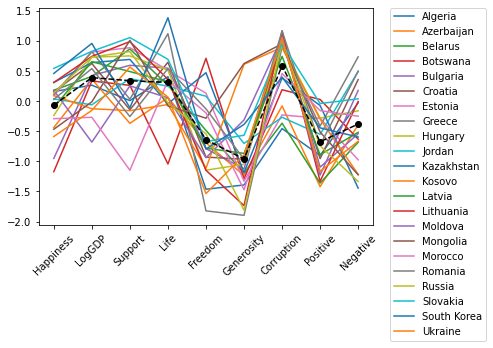

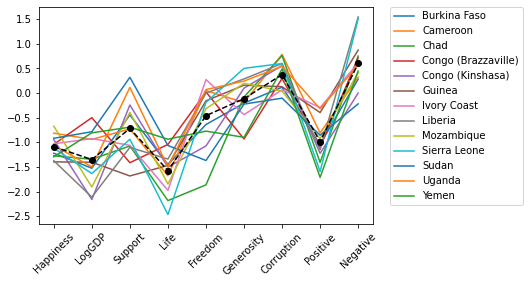

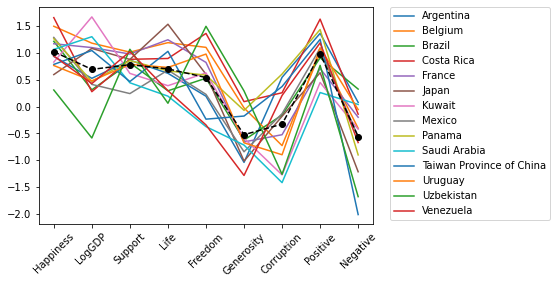

In [15]:
def plot_cluster_and_centroid(label):
    X_scaled_clustered[X_scaled_clustered.klabel==label][key_vars].T.plot(legend=True)
    plt.plot(kcluster.cluster_centers_[label], 'ko--')
    plt.xticks(range(9), key_vars, rotation=45)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)

plot_cluster_and_centroid(0)
plot_cluster_and_centroid(3)
plot_cluster_and_centroid(6)

In [16]:
df2_clustered.groupby(['klabel', 'region']).size()

klabel  region                            
0       Central and Eastern Europe             9
        Commonwealth of Independent States     6
        East Asia                              2
        Middle East and North Africa           3
        Sub-Saharan Africa                     1
        Western Europe                         1
1       East Asia                              1
        Middle East and North Africa           2
        North America and ANZ                  4
        Southeast Asia                         1
        Western Europe                        12
2       Central and Eastern Europe             5
        Commonwealth of Independent States     2
        Middle East and North Africa           8
        Sub-Saharan Africa                     2
3       Middle East and North Africa           1
        Sub-Saharan Africa                    12
4       Central and Eastern Europe             3
        Latin America and Caribbean            1
        Middle East and No

In [18]:
!jupyter nbconvert --to pdf "Gerald G - Module 3 Unsupervised Learning Assignment.ipynb"

[NbConvertApp] Converting notebook Gerald G - Module 3 Unsupervised Learning Assignment.ipynb to pdf
[NbConvertApp] Support files will be in Gerald G - Module 3 Unsupervised Learning Assignment_files/
[NbConvertApp] Making directory ./Gerald G - Module 3 Unsupervised Learning Assignment_files
[NbConvertApp] Making directory ./Gerald G - Module 3 Unsupervised Learning Assignment_files
[NbConvertApp] Making directory ./Gerald G - Module 3 Unsupervised Learning Assignment_files
[NbConvertApp] Making directory ./Gerald G - Module 3 Unsupervised Learning Assignment_files
[NbConvertApp] Making directory ./Gerald G - Module 3 Unsupervised Learning Assignment_files
[NbConvertApp] Writing 68358 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF success